## EDA

### Initial data understanding

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

df_raw = pd.read_csv('data/proj_machine_readings.csv')
df = df_raw.copy()   

In [2]:
df.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


In [3]:
print(df.shape)
df.info()

(100000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000 non-null  int64  
 10  failure_type              100000 non-null  str    
 11  downtime_risk             100000 non-null  float64
 12  maintenance_required      100000 non-null  int64  
dtypes: float64(6), int64(5), str(2)
memory usag

In [4]:
# Insights: initial data
# 100,000 rows, 13 columns.
# Only temperature has nulls: 14,000 missing (14%).
# timestamp is a string -> convert to datetime.
# machine_id is int64 but it is a category label -> convert to category.

In [5]:
num_cols = ['temperature', 'vibration', 'humidity', 'pressure', 'energy_consumption']
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature,86000.0,75.034410,10.036257,35.55,68.28,75.090,81.78,121.94
vibration,100000.0,43.324232,29.134306,-106.98,37.22,48.635,59.25,113.80
humidity,100000.0,54.995401,14.437960,30.00,42.52,54.980,67.50,80.00
pressure,100000.0,3.000405,1.152399,1.00,2.00,3.010,4.00,5.00
energy_consumption,100000.0,2.747064,1.297865,0.50,1.63,2.740,3.87,5.00


In [6]:
# Insights: value ranges
# vibration has negative values (min -106.98), which is not correct -> investigate later.
# temperature: 14,000 nulls; max 121.94 is far above the mean (75), so check for outliers.
# humidity (30-80), pressure (1-5), energy (0.5-5) look valid.

In [7]:
# Categorical derived columns: count of each value
for col in ['machine_status', 'anomaly_flag', 'failure_type']:
    display(df[col].value_counts().to_frame())

# Numeric derived columns: summary numbers
display(df[['predicted_remaining_life']].describe().T)

# downtime_risk: which different values does it have?
display(df['downtime_risk'].value_counts().to_frame())

,count
machine_status,
1,80091
2,10057
0,9852


,count
anomaly_flag,
0,91084
1,8916


,count
failure_type,
Normal,91899
Vibration Issue,3129
Overheating,1989
Pressure Drop,1969
Electrical Fault,1014


,count,mean,std,min,25%,50%,75%,max
predicted_remaining_life,100000.0,234.26916,150.063062,1.0,97.0,230.0,365.0,499.0


,count
downtime_risk,
0.00,91084
1.00,8904
0.98,3
0.99,3
0.97,2
0.92,1
0.94,1
0.88,1
0.93,1


In [8]:
# Insights: derived columns
# All derived columns:
#   None of them have missing or odd values, so there is nothing to clean.

# predicted_remaining_life:
#   It ranges from 1 to 499 (median 230), so the values look reasonable.

# downtime_risk:
#   It is almost always 0 (91,084 rows) or 1 (8,904 rows). Only 12 rows have a value in between.
#   91,084 rows are 0, and 8,904 + 12 = 8,916 rows are not 0.

# anomaly_flag:
#   8,916 rows have 1, and 91,084 rows have 0.

# downtime_risk and anomaly_flag:
#   They have the same number of non-zero rows (8,916), so the two may carry the same information.

# Possible problem:
#   These columns are made from other data, so they may already contain the answer (maintenance_required), 
#   which would make it easy for a model to predict.

### Column-by-column investigation and cleaning
1. **timestamp and machine_id**: convert to datetime / category, time range, rows per machine
2. **temperature**: nulls, spread across machines, fill with median
3. **vibration**: min/max, negatives, compare, fix with abs()
4. **humidity, pressure & energy**: range check, outliers

#### timestamp and machine_id

In [9]:
# Fix types so the columns are proper
df['timestamp'] = pd.to_datetime(df['timestamp'])        
df['machine_id'] = df['machine_id'].astype('category')  
print(df.dtypes)

timestamp                   datetime64[us]
machine_id                        category
temperature                        float64
vibration                          float64
humidity                           float64
pressure                           float64
energy_consumption                 float64
machine_status                       int64
anomaly_flag                         int64
predicted_remaining_life             int64
failure_type                           str
downtime_risk                      float64
maintenance_required                 int64
dtype: object


In [10]:
# Time check: when does the data start and end, and does any timestamp repeat?
print('Time range:', df['timestamp'].min(), 'to', df['timestamp'].max())   # start and end dates
print('Time span:', df['timestamp'].max() - df['timestamp'].min())         # how long that is
print('Unique dates:', df['timestamp'].dt.date.nunique())                  # number of calendar dates with data
print('Unique timestamps:', df['timestamp'].nunique())                     # compare with number of rows

Time range: 2025-01-01 00:00:00 to 2025-03-11 10:39:00
Time span: 69 days 10:39:00
Unique dates: 70
Unique timestamps: 100000


In [11]:
# Machine check: how many machines, and does each have a similar number of rows (readings)?
print('Machines:', df['machine_id'].nunique())            
print(df['machine_id'].value_counts().describe())

Machines: 50
count      50.000000
mean     2000.000000
std        51.673228
min      1906.000000
25%      1956.250000
50%      2002.500000
75%      2042.500000
max      2092.000000
Name: count, dtype: float64


In [12]:
# how many minutes between one machine's readings?
gaps = df.sort_values('timestamp').groupby('machine_id', observed=True)['timestamp'].diff().dt.total_seconds() / 60
print(gaps.describe())

count    99950.000000
mean        49.973307
std         49.273879
min          1.000000
25%         15.000000
50%         35.000000
75%         69.000000
max        514.000000
Name: timestamp, dtype: float64


In [13]:
# Insights: time span and machines
# Time: data runs from 2025-01-01 00:00 to 2025-03-11 10:39 (69 days 10 hours, covering 70 calendar dates).
# Rows: 100,000 rows, each with a different timestamp -> 1 reading per minute is recorded from one of the 50 machines.
#       Each row comes from one of the 50 machines, so a machine does not report every minute.
# Machines: 50 machines with ~2,000 rows each (min 1,906, max 2,092) -> so every machine has about the same number of rows.
# Gaps: each machine is read about every 50 min on average, but unevenly (median 35 min, longest 514 min).

#### temperature

In [14]:
# Rows where temperature is missing
missing = df[df['temperature'].isna()]
print('Missing rows:', len(missing))

# How many missing rows does each machine have? (summarised over 50 machines)
print(missing['machine_id'].value_counts().describe())

Missing rows: 14000
count     50.000000
mean     280.000000
std       15.193984
min      250.000000
25%      268.500000
50%      280.000000
75%      290.000000
max      314.000000
Name: count, dtype: float64


In [15]:
# Does temperature differ between machines? (median temperature per machine, summarised over 50 machines)
print(df.groupby('machine_id', observed=True)['temperature'].median().describe())
print('Overall median:', df['temperature'].median())

count    50.000000
mean     75.074600
std       0.298156
min      74.460000
25%      74.845000
50%      75.077500
75%      75.285000
max      75.820000
Name: temperature, dtype: float64
Overall median: 75.09


49835    121.94
51902    118.32
95265    117.98
97683    117.27
24370    116.00
Name: temperature, dtype: float64


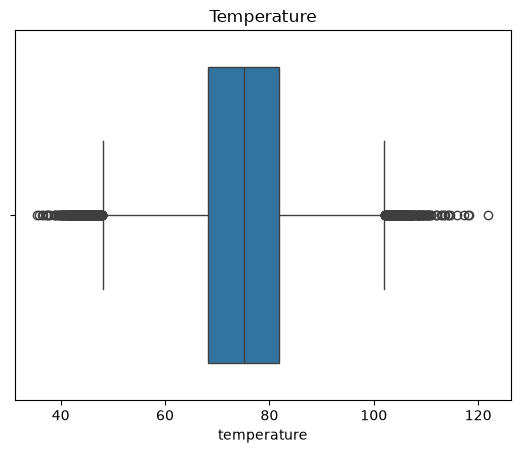

In [16]:
# Show the extreme temperature readings
print(df['temperature'].sort_values(ascending=False).head(5))   # 5 highest readings

# Boxplot: Look for outliers
sns.boxplot(x=df['temperature'])
plt.title('Temperature')
plt.show()

In [17]:
# Fill missing temperature with the overall median
df['temperature'] = df['temperature'].fillna(df['temperature'].median())
print('Missing temperature after fill:', df['temperature'].isna().sum())   

Missing temperature after fill: 0


In [18]:
# Insights: temperature
# 14,000 rows (14%) are missing temperature, spread evenly across machines (250-314 each) so the nulls look random.
# Median temperature per machine is almost the same (74.5 to 75.8, overall median 75.09).
# The highest readings are 116-122, while the middle half of readings is 68-82.
# Decision: fill missing temperature with the overall median.
# Reason: the median is not pulled by extreme readings, so the filled values look like normal readings.

#### vibration

In [19]:
# Find the rows where vibration is negative
neg_vib = df[df['vibration'] < 0]

# How many are there?
print('Negative count:', len(neg_vib))

# What percent of all rows is that?  (negative rows / all rows * 100)
print('Percent:', round(len(neg_vib) / len(df) * 100, 2), '%')

# What do the negative vibration values look like?
print(neg_vib['vibration'].describe())

Negative count: 6703
Percent: 6.7 %
count    6703.000000
mean      -49.914617
std        15.246465
min      -106.980000
25%       -60.050000
50%       -50.020000
75%       -40.025000
max        -0.020000
Name: vibration, dtype: float64


In [20]:
# Compare the negative vibration (with the minus removed) against the normal positive values
pos_vib = df[df['vibration'] >= 0]['vibration']
neg_vib_abs = df[df['vibration'] < 0]['vibration'].abs()   # abs() removes the minus sign

print('Positive values:')
print(pos_vib.describe())
print('Negative values (minus removed):')
print(neg_vib_abs.describe())

Positive values:
count    93297.000000
mean        50.023055
std         14.953973
min          0.100000
25%         39.960000
50%         49.960000
75%         60.110000
max        113.800000
Name: vibration, dtype: float64
Negative values (minus removed):
count    6703.000000
mean       49.914617
std        15.246465
min         0.020000
25%        40.025000
50%        50.020000
75%        60.050000
max       106.980000
Name: vibration, dtype: float64


In [21]:
# Fix: remove the minus sign
df['vibration'] = df['vibration'].abs()
print('Negative count after fix:', (df['vibration'] < 0).sum())  
print(df['vibration'].describe())

Negative count after fix: 0
count    100000.000000
mean         50.015786
std          14.973704
min           0.020000
25%          39.970000
50%          49.960000
75%          60.100000
max         113.800000
Name: vibration, dtype: float64


In [22]:
# Insights: vibration outliers (after the fix)
# Many readings are beyond the whiskers on both sides: below ~10 and above ~90 (up to 113.8).
# These high and low values are possible for a vibration sensor, unlike the negatives, which cannot happen.
# They do not seem to be errors, so they are kept for now.

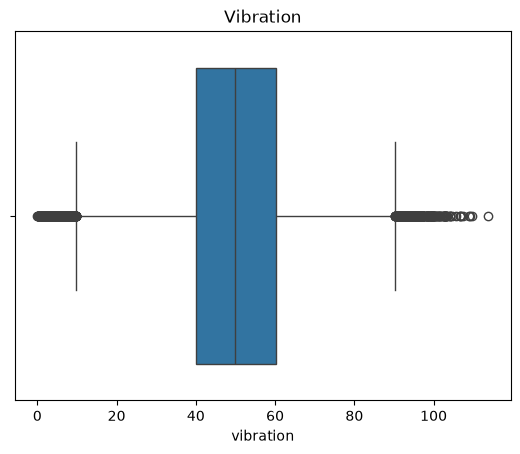

In [23]:
sns.boxplot(x=df['vibration'])
plt.title('Vibration')
plt.show()

In [24]:
# Insights: vibration outliers (after the fix)
# Many readings are beyond the whiskers on both sides: below ~10 and above ~90.
# These high and low values are possible for a vibration sensor, unlike the negatives, which cannot happen.
# They do not seem to be errors, so they are kept for now.

#### humidity, pressure & energy consumption

            humidity       pressure  energy_consumption
count  100000.000000  100000.000000       100000.000000
mean       54.995401       3.000405            2.747064
std        14.437960       1.152399            1.297865
min        30.000000       1.000000            0.500000
25%        42.520000       2.000000            1.630000
50%        54.980000       3.010000            2.740000
75%        67.500000       4.000000            3.870000
max        80.000000       5.000000            5.000000


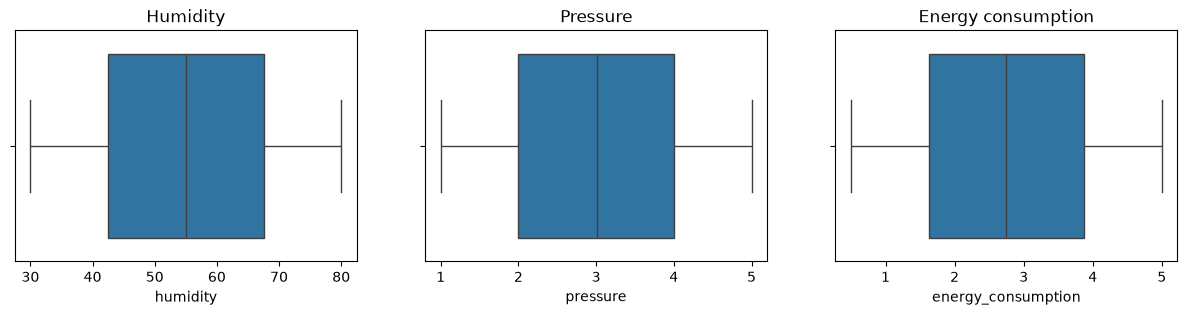

In [25]:
# Summary numbers for the three sensors
print(df[['humidity', 'pressure', 'energy_consumption']].describe())

# Boxplots side by side: are there extreme values?
fig, axes = plt.subplots(1, 3, figsize=(15, 3))   # 1 row, 3 charts

sns.boxplot(x=df['humidity'], ax=axes[0])
axes[0].set_title('Humidity')

sns.boxplot(x=df['pressure'], ax=axes[1])
axes[1].set_title('Pressure')

sns.boxplot(x=df['energy_consumption'], ax=axes[2])
axes[2].set_title('Energy consumption')

plt.show()

In [26]:
# Insights: humidity, pressure, energy consumption
# No nulls, and all values are inside valid ranges (humidity 30-80, pressure 1-5, energy 0.5-5).
# No outliers: the boxplots have no points beyond the whiskers.
# Mean and median are almost equal for each, so the readings are balanced around the middle.
# No cleaning needed.

### Target Balance

,count,percent
maintenance_required,,
0,80303,80.3
1,19697,19.7


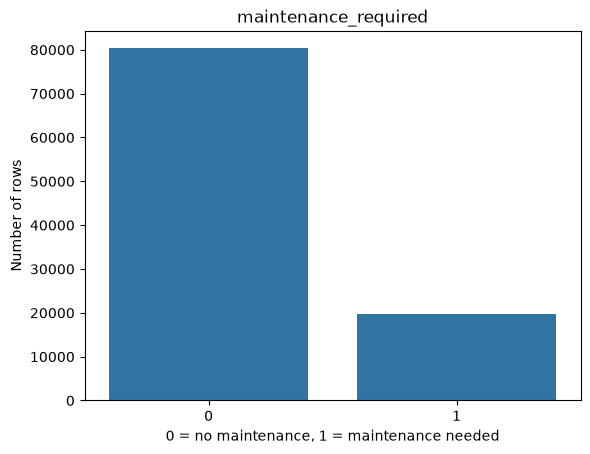

In [27]:
# How many rows need maintenance (1) and how many do not (0)?
counts = df['maintenance_required'].value_counts()
display(pd.DataFrame({'count': counts, 'percent': (counts / len(df) * 100).round(1)}))

# Bar charts
sns.countplot(x=df['maintenance_required'])
plt.title('maintenance_required')
plt.xlabel('0 = no maintenance, 1 = maintenance needed')
plt.ylabel('Number of rows')
plt.show()

In [28]:
# Insights: target balance
# 80.3% of rows are 0 (no maintenance) and 19.7% are 1 (maintenance needed), so the target is imbalanced.
# The model could learn to predict 0 almost every time and still be right most of the time, 
# while missing the machines that need maintenance.
# So the imbalance needs to be handled when training the models, 
# for example with class weights, and the results should be judged with recall or F1 as well as accuracy.

### Correlations & Leakage check

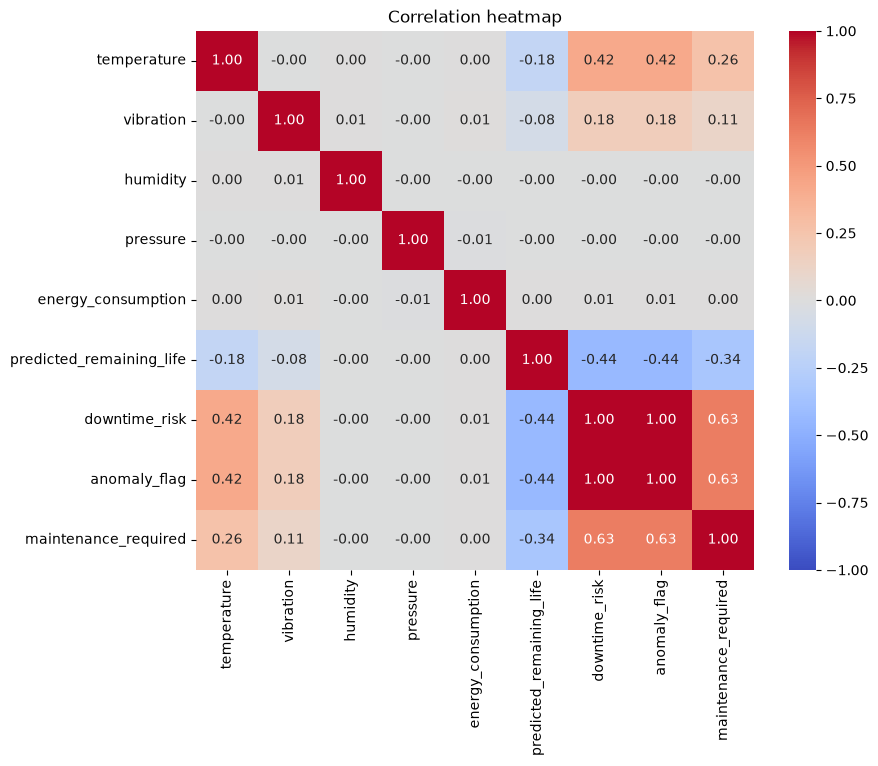

In [29]:
# Correlation between selected columns and the target (the sensors, predicted_remaining_life, downtime_risk and anomaly_flag)
corr_cols = num_cols + ['predicted_remaining_life', 'downtime_risk', 'anomaly_flag', 'maintenance_required']
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation heatmap')
plt.show()

In [30]:
# Insights: correlations (Pearson's correlation)
# temperature (0.26) and vibration (0.11) have a weak positive correlation with maintenance_required.
# humidity, pressure and energy_consumption are about 0.
# The sensors have a correlation of about 0 with each other, so there is no linear relationship between them.
# downtime_risk and anomaly_flag have the strongest correlation with the target (0.63).
# predicted_remaining_life has a negative correlation (-0.34): the less life left, the more likely maintenance is needed.
# downtime_risk also correlates with temperature (0.42) and vibration (0.18), so it may be built from the sensor readings.
# anomaly_flag and downtime_risk have a correlation of 1.00 with each other and 
# the same correlation with each of the other columns in the heatmap, so they carry the same information. 
# Only one of them needs to be kept as a model feature.

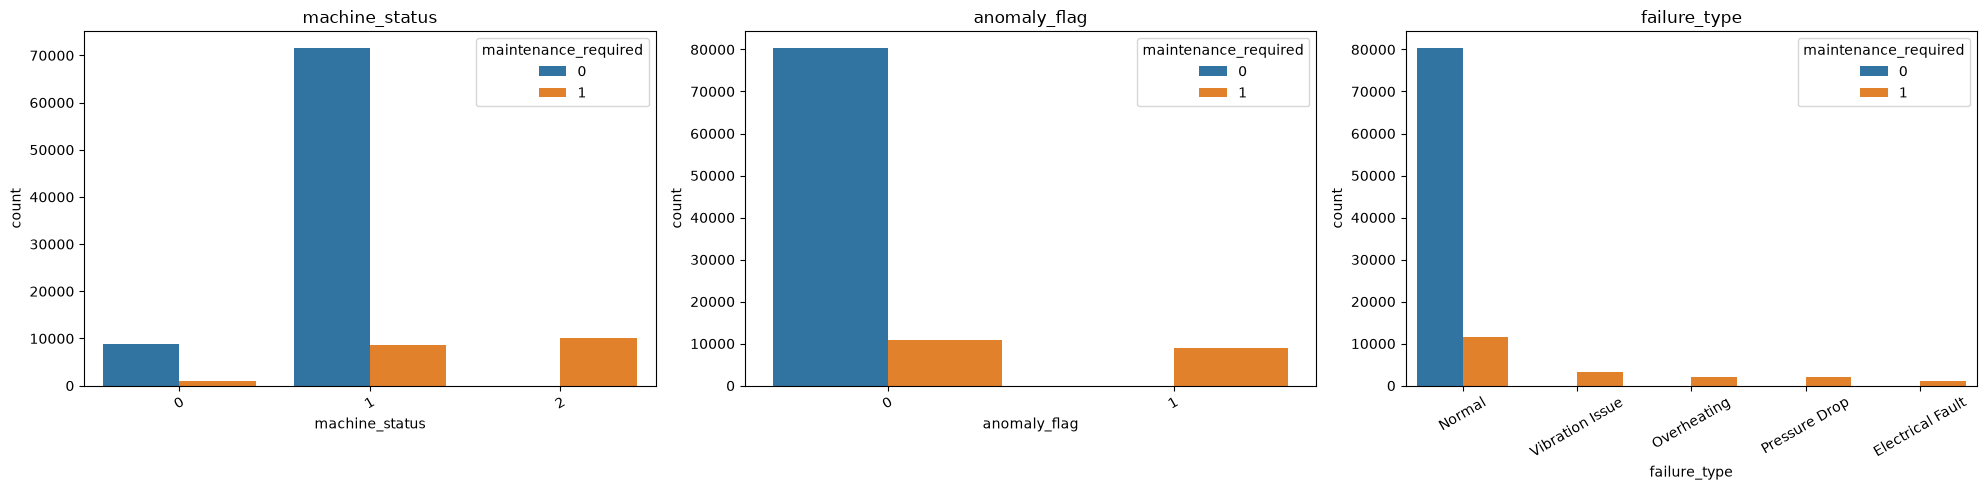

In [31]:
# For each of the three columns: count of rows for each value, split by maintenance_required
cat_cols = ['machine_status', 'anomaly_flag', 'failure_type']
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for i in range(3):
    sns.countplot(data=df, x=cat_cols[i], hue='maintenance_required', ax=axes[i])
    axes[i].set_title(cat_cols[i])
    axes[i].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [32]:
# Number of rows with maintenance_required = 0 and 1, for each value of each column
for c in ['machine_status', 'anomaly_flag', 'failure_type']:
    display(df.groupby(c)['maintenance_required'].value_counts().to_frame())

count
machine_status maintenance_required       
0              0                      8776
               1                      1076
1              0                     71527
               1                      8564
2              1                     10057

count
anomaly_flag maintenance_required       
0            0                     80303
             1                     10781
1            1                      8916

count
failure_type     maintenance_required       
Electrical Fault 1                      1014
Normal           0                     80303
                 1                     11596
Overheating      1                      1989
Pressure Drop    1                      1969
Vibration Issue  1                      3129

In [33]:
# Insights: category derived columns vs maintenance_required
# machine_status: 
#   idle (0) and running (1) are mostly 0, with some 1. 
#   Failure (2) has no rows with 0, so all 10,057 failure rows need maintenance.

# anomaly_flag: 
#   no anomaly (0) is mostly 0, with some 1. 
#   Anomaly (1) has no rows with 0, so all 8,916 anomaly rows need maintenance.

# failure_type: 
#   Normal is mostly 0, with some 1. 
#   The other four types have no rows with 0, so all 8,101 of those rows need maintenance (the four counts added up).

# In all three columns, one group always needs maintenance, so each column is strongly related to the target 
# and a model could use it to predict the target directly.
# The other groups (machine_status 0 and 1, anomaly_flag = 0, failure_type = Normal) 
# still contain both 0 and 1, so for those rows the column does not show whether maintenance is needed.

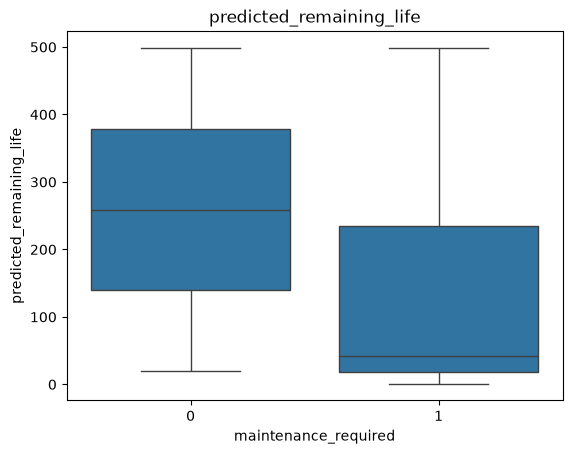

In [34]:
# Boxplot of predicted_remaining_life, split by maintenance_required
sns.boxplot(data=df, x='maintenance_required', y='predicted_remaining_life')
plt.title('predicted_remaining_life')
plt.show()

In [35]:
# Number of rows for each downtime_risk value, for maintenance_required = 0 and 1
display(df.groupby('maintenance_required')['downtime_risk'].value_counts().to_frame())

count
maintenance_required downtime_risk       
0                    0.00           80303
1                    0.00           10781
                     1.00            8904
                     0.98               3
                     0.99               3
                     0.97               2
                     0.92               1
                     0.94               1
                     0.88               1
                     0.93               1

In [36]:
# Insights: numeric derived columns vs maintenance_required
# predicted_remaining_life: 
#   The median is much lower for rows that need maintenance (1) than for rows that do not (0).
#   This means machines that need maintenance usually have little remaining life left, which makes sense.
#   The two boxes overlap, so many rows from both groups have similar remaining life values. 
#   Both groups also reach about 500, so some machines that need maintenance still have a lot of remaining life.
#   So a low value of remaining life tends to point towards maintenance, but not always.

# downtime_risk: 
#   Rows that need maintenance (1) are a mix of no risk (0.00) and high risk (mostly 1.00).
#   Rows that do not need maintenance (0) all have no risk (0.00), in all 80,303 rows.
#   So a row with downtime_risk above 0 always needs maintenance.
#   A downtime_risk of 0 does not show whether maintenance is needed, 
#   because 10,781 rows that need maintenance also have a risk of 0.

In [37]:
# Number of rows for each downtime_risk value, for anomaly_flag = 0 and 1
display(df.groupby('anomaly_flag')['downtime_risk'].value_counts().to_frame())

count
anomaly_flag downtime_risk       
0            0.00           91084
1            1.00            8904
             0.98               3
             0.99               3
             0.97               2
             0.92               1
             0.94               1
             0.88               1
             0.93               1

In [38]:
# Insights: downtime_risk vs anomaly_flag
# When anomaly_flag = 0, downtime_risk is 0 in all 91,084 rows.
# When anomaly_flag = 1, downtime_risk is above 0 in all 8,916 rows (1.00 in 8,904 rows, and between 0.88 and 0.99 in the other 12).
# So anomaly_flag and downtime_risk mark the same rows, and only one of them is needed.

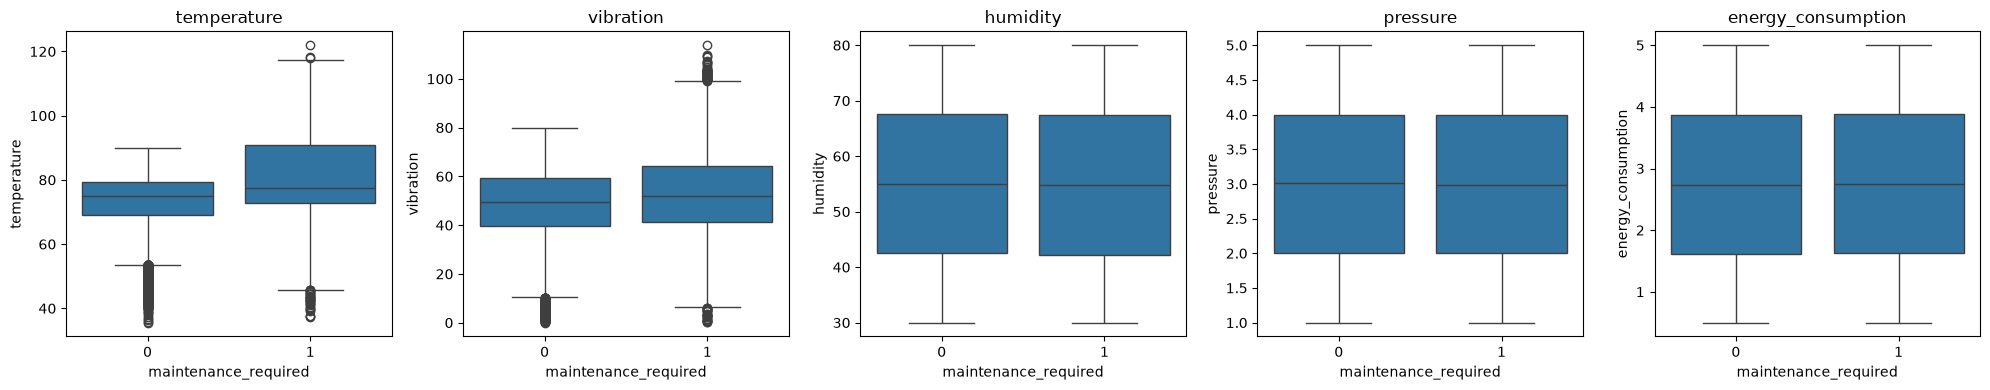

In [39]:
# Boxplot of each sensor, split by maintenance_required
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i in range(5):
    sns.boxplot(data=df, x='maintenance_required', y=num_cols[i], ax=axes[i])
    axes[i].set_title(num_cols[i])
plt.tight_layout()
plt.show()

In [40]:
# Insights: sensors vs maintenance_required
# temperature: 
#   Rows that need maintenance (1) have a higher median and a wider spread than rows that do not (0). 
#   The highest values only appear in rows that need maintenance (1).

# vibration: 
#   The highest values only appear in rows that need maintenance (1).

# humidity, pressure and energy_consumption: 
#   The boxes look the same for rows that need maintenance (1) and rows that do not (0), 
#   so these sensor readings do not show a clear difference between the two.

# This matches the correlation heatmap, where temperature (0.26) and vibration (0.11)
# had the highest correlation with the target among the sensors, and the other three were about 0.
# The highest temperature and vibration values only appear in rows that need maintenance (1),
# so they are kept as possible real readings.

### Per-machine and over-time patterns

count     50.000000
mean     393.940000
std       21.626146
min      348.000000
25%      377.250000
50%      398.000000
75%      411.500000
max      433.000000
Name: maintenance_required, dtype: float64

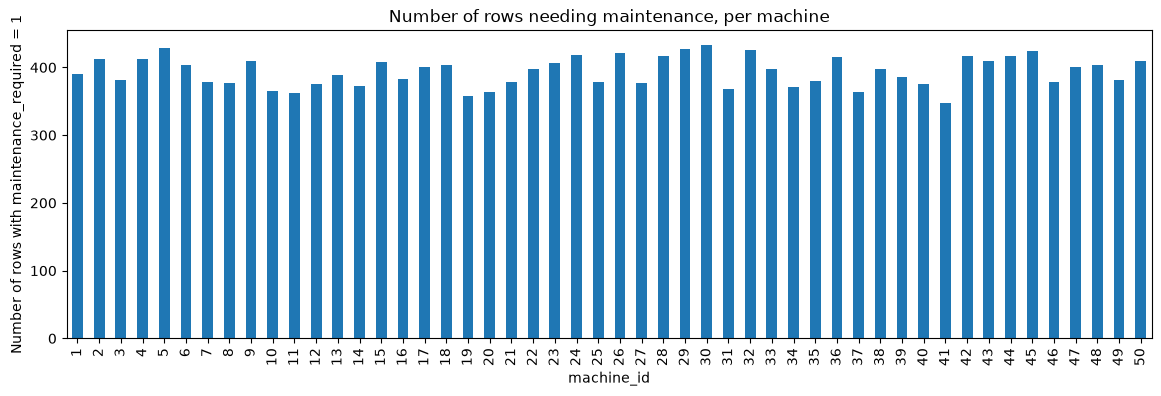

In [41]:
# Number of rows that need maintenance, for each machine (the sum of a column of 0s and 1s)
machine_count = df.groupby('machine_id', observed=True)['maintenance_required'].sum()
display(machine_count.describe())

# Bar chart, one bar per machine
plt.figure(figsize=(14, 4))
machine_count.plot(kind='bar')
plt.title('Number of rows needing maintenance, per machine')
plt.xlabel('machine_id')
plt.ylabel('Number of rows with maintenance_required = 1')
plt.show()

In [42]:
# Insights: maintenance_required per machine
# The number of rows needing maintenance is similar across all 50 machines, from 348 to 433, with an average of about 394.
# No machine stands out as needing maintenance much more or much less often than the others.
# So machine_id is unlikely to help predict maintenance_required on its own.

count    70.000000
mean      0.197044
std       0.010770
min       0.168056
25%       0.189583
50%       0.197917
75%       0.203993
max       0.221528
Name: maintenance_required, dtype: float64

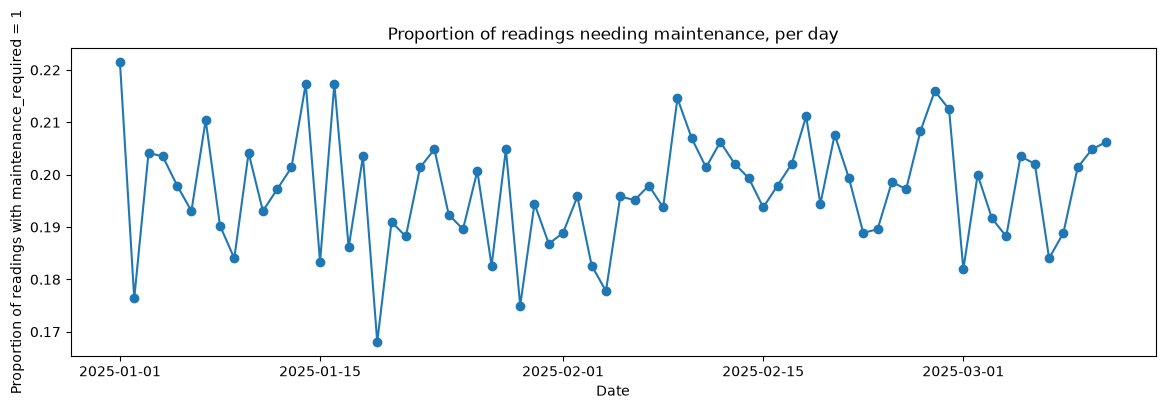

In [43]:
# Proportion of readings that need maintenance, for each day (the mean of a column of 0s and 1s)
daily_rate = df.groupby(df['timestamp'].dt.date)['maintenance_required'].mean()
display(daily_rate.describe())

# Line chart, one point per day
plt.figure(figsize=(14, 4))
daily_rate.plot(marker='o')
plt.title('Proportion of readings needing maintenance, per day')
plt.xlabel('Date')
plt.ylabel('Proportion of readings with maintenance_required = 1')
plt.show()

In [44]:
# Average proportion in the first 35 days and in the last 35 days
print(daily_rate.iloc[:35].mean())
print(daily_rate.iloc[35:].mean())

0.19456349206349208
0.19952380952380952


In [45]:
# Insights: maintenance_required over time
# The proportion of readings needing maintenance changes from day to day, 
# between about 0.17 and 0.22, but stays around the overall 0.20.
# There is no clear upward or downward trend across the 70 days. 
# The average proportion is about 0.195 in the first 35 days and about 0.200 in the last 35 days.
# So the proportion of maintenance readings is stable over time, 
# which means a time-based split for train and test would give both sets a similar proportion of maintenance readings.

### Feature Engineering

In [46]:
# New columns: hour of the day and day of the week, taken from timestamp (0 = Monday)
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_of_week
display(df[['timestamp', 'hour', 'day_of_week']].head())

,timestamp,hour,day_of_week
0,2025-01-01 00:00:00,0,2
1,2025-01-01 00:01:00,0,2
2,2025-01-01 00:02:00,0,2
3,2025-01-01 00:03:00,0,2
4,2025-01-01 00:04:00,0,2


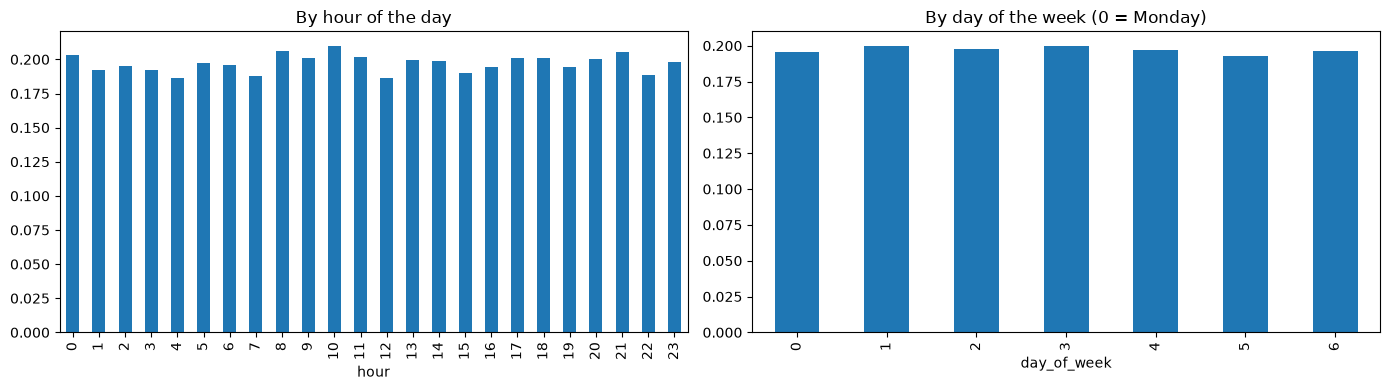

In [47]:
# Proportion of readings needing maintenance, by hour and by day of the week
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby('hour')['maintenance_required'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title('By hour of the day')
df.groupby('day_of_week')['maintenance_required'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title('By day of the week (0 = Monday)')
plt.tight_layout()
plt.show()

In [48]:
# Insights: hour and day_of_week
# The proportion of readings needing maintenance is about 0.20 at every hour of the day and on every day of the week.
# So hour and day_of_week do not show a clear relationship with maintenance_required, and they will not be used as features.

# Feature engineering summary
# Time features (hour, day_of_week) do not show a clear relationship with maintenance_required, so no new features are added.